<a href="https://colab.research.google.com/github/SitiMutmainah15/PEMBELAJARAN-MESIN_GENAP_2026/blob/main/JS08/TugasLab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import HDBSCAN
from sklearn.decomposition import PCA

iris = load_iris()

X = iris.data
y = iris.target

print("Jumlah data:", X.shape[0])
print("Jumlah fitur:", X.shape[1])
print("Jenis bunga:", iris.target_names)

Jumlah data: 150
Jumlah fitur: 4
Jenis bunga: ['setosa' 'versicolor' 'virginica']


In [2]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

model = HDBSCAN(
    min_cluster_size=10,
    min_samples=5
)

labels = model.fit_predict(X_scaled)

In [3]:
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = sum(labels == -1)

print("Jumlah cluster:", n_clusters)
print("Jumlah noise:", n_noise)

print("\nJumlah data setiap cluster:")
print(pd.Series(labels).value_counts().sort_index())

Jumlah cluster: 2
Jumlah noise: 2

Jumlah data setiap cluster:
-1     2
 0    50
 1    98
Name: count, dtype: int64


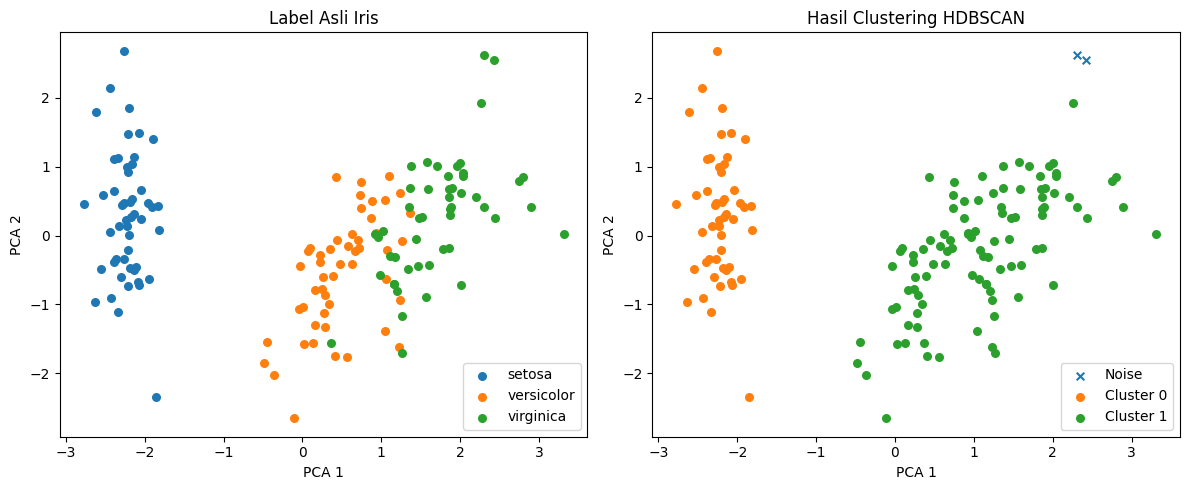

In [4]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Visualisasi label asli
for i, nama in enumerate(iris.target_names):
    mask = y == i
    axes[0].scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        label=nama, s=30
    )

axes[0].set_title("Label Asli Iris")
axes[0].legend()

# Visualisasi Hdbscan
for cluster in np.unique(labels):
    mask = labels == cluster
    nama = "Noise" if cluster == -1 else f"Cluster {cluster}"
    marker = "x" if cluster == -1 else "o"

    axes[1].scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        label=nama, marker=marker, s=30
    )

axes[1].set_title("Hasil Clustering HDBSCAN")
axes[1].legend()

for ax in axes:
    ax.set_xlabel("PCA 1")
    ax.set_ylabel("PCA 2")

plt.tight_layout()
plt.show()

In [5]:
hasil = pd.DataFrame({
    "Jenis_Asli": iris.target_names[y],
    "Cluster": labels
})

print(pd.crosstab(
    hasil["Jenis_Asli"],
    hasil["Cluster"]
))

Cluster     -1   0   1
Jenis_Asli            
setosa       0  50   0
versicolor   0   0  50
virginica    2   0  48


Sesuai dengan hasil pengujian menggunakan metode Hdbscan pada dataset Iris, didapat 2 cluster dari 150 data dan 2 data termasuk noise. Cluster 0 50 data dan cluster 1 98 data. Jika dibandingkan dengan label asli yang memiliki 3 jenis bunga, hasilnya belum sepenuhnya sesuai. Bunga Setosa berhasil dikelompokkan secara terpisah, sedangkan Versicolor dan Virginica masih berada dalam satu cluster. Ini menunjukkan jika model bisa memisahkan data yang memiliki karakteristik berbeda, tetapi belum bisa membentuk kelompok yang sepenuhnya sesuai dengan jenis bunga aslinya.